In [1]:
import sys
import pickle
from codebot.tokenizer import train_bpe

sys.path.append(".")

vocab_size = 1000
text = open("codebot/tiny_codes.txt", encoding = "utf-8").read()
merge_rules = train_bpe(text, vocab_size)

with open("codebot/merge_rules.pkl", "wb") as f:
    pickle.dump(merge_rules, f)

Training BPE: 100%|██████████| 743/743 [11:33<00:00,  1.07it/s]


In [2]:
import sys
from codebot.tokenizer import BPETokenizer

sys.path.append(".")

tokenizer = BPETokenizer.load_from("codebot/merge_rules.pkl")

print("처음 학습된 10개")
for token_id in range(256, 266):
    byte_seq = tokenizer.id_to_bytes[token_id]
    text = byte_seq.decode("utf-8", errors = "replace")
    print(token_id, text)

print("마지막 학습된 10개")
for token_id in range(990, 1000):
    byte_seq = tokenizer.id_to_bytes[token_id]
    text = byte_seq.decode("utf-8", errors = "replace")
    print(token_id, text)

sample_text = open("codebot/tiny_codes.txt", encoding = "utf-8").read()[:10000]

byte_count = len(sample_text.encode("utf-8"))
ids = tokenizer.encode(sample_text)
ids_count = len(ids)
compression_ratio = byte_count / ids_count

print("바이트수 :", byte_count)
print("토큰수 :", ids_count)
print("압축률 :", compression_ratio)

처음 학습된 10개
256   
257     
258 in
259    
260 re
261 or
262  =
263 st
264 te
265 
   
마지막 학습된 10개
990 Error
991  ''
992 atter
993 St
994 thod
995  on
996 cle
997  R
998 ery
999 <|endoftext|>
바이트수 : 10000
토큰수 : 4709
압축률 : 2.1235931195582927


In [3]:
import sys
import numpy as np
from codebot.tokenizer import BPETokenizer

sys.path.append(".")

tokenizer = BPETokenizer.load_from("codebot/merge_rules.pkl")

text = open("codebot/tiny_codes.txt", encoding = "utf-8").read()
ids = tokenizer.encode(text, show_progress = True)

ids_array = np.array(ids, dtype = np.uint16)
ids_array.tofile("codebot/tiny_codes.bin")

print(len(ids_array))
print(ids_array[:20])

Encoding: 100%|██████████| 43671/43671 [03:52<00:00, 188.22it/s]

2677398
[116 528 821 262 544  10 119 717 660  58 265 268 528 107 262 595 338  69
 669 273]


In [4]:
import numpy as np
import sys
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import matplotlib.pyplot as plt
from itertools import cycle
from tqdm import tqdm

from codebot.model import GPT
from codebot.utils import get_device

sys.path.append(".")

device = get_device()
data_path = "codebot/tiny_codes.bin"
tokenizer_path = "codebot/merge_rules.pkl"
model_save_path = "codebot/model_pretrain.pt"

context_len = 256
vocab_size = 1000
batch_size = 32
learning_rate = 3e-4

max_iters = 20000
embed_dim = 384
n_head = 6
n_layer = 6
ff_dim = 4 * embed_dim
dropout_rate = 0.1

In [5]:
class TokenDataset(Dataset):
    def __init__(self, tokens, context_len):
        self.tokens = torch.tensor(tokens, dtype = torch.long)
        self.context_len = context_len

    def __len__(self):
        return len(self.tokens) - self.context_len

    def __getitem__(self, idx):
        x = self.tokens[idx:idx + self.context_len]
        y = self.tokens[idx + 1: idx + self.context_len + 1]
        return x, y

In [6]:
ids = np.fromfile(data_path, dtype = np.uint16)
dataset = TokenDataset(ids, context_len)
dataloader = DataLoader(dataset, batch_size = batch_size, shuffle = True)

model = GPT(vocab_size = vocab_size,
            max_context_len = context_len,
            embed_dim = embed_dim,
            n_head = n_head,
            n_layer = n_layer,
            ff_dim = ff_dim,
            dropout_rate = dropout_rate).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr = learning_rate)

total_params = sum(p.numel() for p in model.parameters())
print("파라미터수 :", total_params)

losses = []
data_iter = cycle(dataloader)
pbar = tqdm(range(max_iters))

파라미터수 : 11121640


  0%|          | 0/20000 [00:00<?, ?it/s]

100%|██████████| 20000/20000 [40:47<00:00,  8.17it/s, loss=0.6544]
C:\Users\KDS-30\AppData\Local\Temp\ipykernel_4508\4120022976.py:23: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  plt.savefig("loss_pretrain.png")
C:\Users\KDS-30\AppData\Local\Temp\ipykernel_4508\4120022976.py:23: UserWarning: Glyph 48373 (\N{HANGUL SYLLABLE BOG}) missing from font(s) DejaVu Sans.
  plt.savefig("loss_pretrain.png")
C:\Users\KDS-30\AppData\Local\Temp\ipykernel_4508\4120022976.py:23: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  plt.savefig("loss_pretrain.png")
C:\Users\KDS-30\AppData\Local\Temp\ipykernel_4508\4120022976.py:23: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.savefig("loss_pretrain.png")
c:\Users\KDS-30\Desktop\class\11_bot\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  f

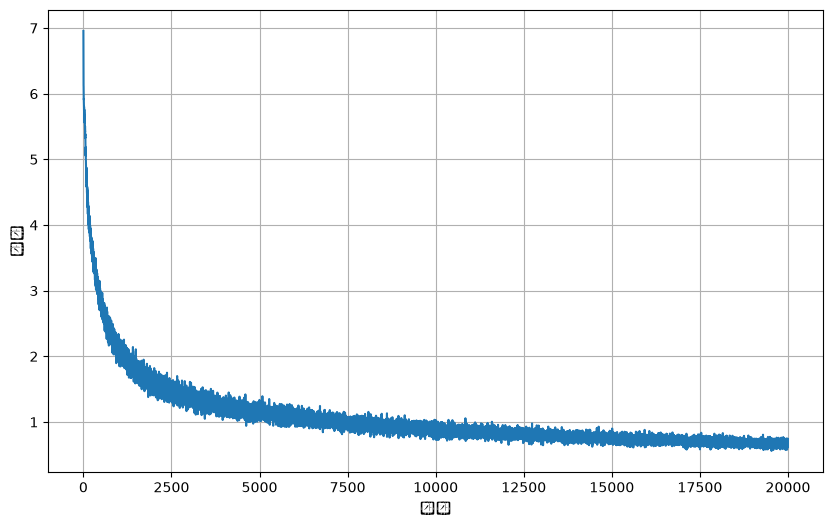

In [7]:
pbar = tqdm(range(max_iters))
for i in pbar:
    batch_x, batch_y = next(data_iter)
    batch_x, batch_y = batch_x.to(device), batch_y.to(device)

    logits = model(batch_x)

    loss = F.cross_entropy(logits.view(-1, logits.size(-1)), batch_y.view(-1))

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    losses.append(loss.item())
    pbar.set_postfix({"loss": f"{loss.item():.4f}"})

plt.figure(figsize = (10, 6))
plt.plot(losses)
plt.xlabel("반복")
plt.ylabel("손실")
plt.grid(True)
plt.savefig("loss_pretrain.png")

model.save(model_save_path)

In [8]:
import sys
sys.path.append(".")

import torch
import torch.nn.functional as F
from codebot.model import GPT
from codebot.tokenizer import BPETokenizer
from codebot.utils import get_device
from codebot.utils import generate

device = get_device()
print(device)

model_save_path = "codebot/model_pretrain.pt"
tokenizer_path = "codebot/merge_rules.pkl"

prompt = "def"
max_new_tokens = 200
temperature = 1.0

tokenizer = BPETokenizer.load_from(tokenizer_path)
model = GPT.load_from(model_save_path, device = device)

cuda


In [9]:
for i in range(5):
    print(i)
    generated_text = generate(model = model,
                              tokenizer = tokenizer,
                              prompt = prompt,
                              max_new_tokens = max_new_tokens,
                              temperature = temperature)
    print(generated_text)
    print()

0
def prepend(self,{,true):
        new_node = Node(Mad):
        if not isinstance(tree, atn), node):
            self.prev = node
        else:
            if node.prev is not None:
                self.queue.append(current.val, node.right)
                node.right = node
            else:
                prev = current.val
                break
            current.val = current
            self.head.val = node.val


1
defumulative_five(a):
    # calculate the average of the series
    average = sum(average) / len(average)
    # calculate the average
    avg = sum(average) / len(average)

    # display the average average
    avg = sum(average) / len(average)
    print("Average of the list is: {}".format(average))

# Output
Average of the list of numbers
AverageAverage


2
def contains_chars(s):
    start = 0
    end = len(s) - 1

    while start < end:
        c = s[start:end + 1]
        start += 1
        end += 1

    return s[:end]

s = "forgeeksskeegfor"
print("ube: ",ube_com

In [10]:
# Supervised Finetune 지도 미세조정

import sys
sys.path.append(".")

import json
from codebot.tokenizer import BPETokenizer

tokenizer = BPETokenizer.load_from("codebot/merge_rules.pkl")

with open("codebot/tiny_codes_sft.json") as f:
    data = json.load(f)

item = data[0]
print(item)

# 알파카 포멧
text = f"### Instruction:\n{item["instruction"]}\n\n### Response:\n{item["response"]}<|endoftext|>"
print(text)

ids = tokenizer.encode(text)
print(ids)

{'instruction': 'Hello', 'response': 'Hello. What can I help you with?'}
### Instruction:
Hello

### Response:
Hello. What can I help you with?<|endoftext|>
[35, 35, 35, 962, 519, 117, 389, 58, 10, 846, 10, 10, 35, 35, 35, 752, 568, 58, 10, 846, 46, 840, 104, 277, 280, 356, 473, 708, 108, 112, 930, 657, 63, 999]


In [11]:
import sys
sys.path.append(".")

from itertools import cycle
import json
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm
from codebot.model import GPT
from codebot.tokenizer import BPETokenizer
from codebot.utils import get_device

In [12]:
device = get_device()
print(device)
data_path = "codebot/tiny_codes_sft.json"
tokenizer_path = "codebot/merge_rules.pkl"
pretrain_model_path = "codebot/model_pretrain.pt"
sft_model_save_path = "codebot/model_sft.pt"

context_len = 256
batch_size = 32
learning_rate = 3e-4
max_iters = 500

cuda


In [13]:
class SFTDataset(Dataset):
    def __init__(self, data_path, tokenizer, context_len):
        self.tokenizer = tokenizer
        self.context_len = context_len
        self.samples = []

        with open(data_path) as f:
            data = json.load(f)

        for item in data:
            ids, labels = self._create_sample(item["instruction"], item["response"])
            self.samples.append((ids, labels))

    def _create_sample(self, instruction, response):
        prompt = f"### Instruction\n{instruction}\n\n### Response:\n"
        response = f"{response}<|endoftext|>"
        
        prompt_ids = self.tokenizer.encode(prompt)
        response_ids = self.tokenizer.encode(response)

        ids = prompt_ids + response_ids
        labels = [-100] * len(prompt_ids) + response_ids

        ids = ids[:-1]
        labels = labels[1:]

        pad_len = self.context_len - len(ids)
        if pad_len > 0:
            ids = ids + [0] * pad_len
            labels = labels + [-100] * pad_len
        elif pad_len < 0:
            ids = ids[:self.context_len]
            labels = labels[:self.context_len]

        return ids, labels

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ids, labels = self.samples[idx]
        return torch.tensor(ids, dtype = torch.long), torch.tensor(labels, dtype = torch.long)

In [14]:
tokenizer = BPETokenizer.load_from(tokenizer_path)
dataset = SFTDataset(data_path, tokenizer, context_len)
dataloader = DataLoader(dataset, batch_size = batch_size, shuffle = True)

model = GPT.load_from(pretrain_model_path, device = device)
optimizer = torch.optim.AdamW(model.parameters(), lr = learning_rate)

losses = []
data_iter = cycle(dataloader)

100%|██████████| 500/500 [00:57<00:00,  8.69it/s, loss=0.0682]


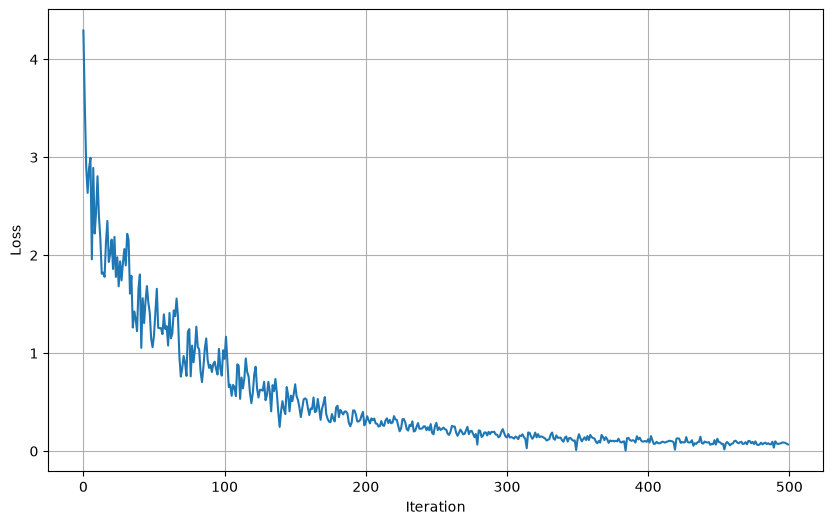

In [15]:
pbar = tqdm(range(max_iters))

for i in pbar:
    batch_x, batch_y = next(data_iter)
    batch_x, batch_y = batch_x.to(device), batch_y.to(device)

    logits = model(batch_x)
    loss = F.cross_entropy(logits.view(-1, logits.size(-1)),
                           batch_y.view(-1),
                           ignore_index = -100)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    pbar.set_postfix({"loss": f"{loss.item():.4f}"})

plt.figure(figsize = (10, 6))
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.savefig("loss_sft.png")

model.save(sft_model_save_path)

In [1]:
import sys
sys.path.append(".")

from codebot.model import GPT
from codebot.tokenizer import BPETokenizer
from codebot.utils import generate, get_device

device = get_device()
print(device)

model_path = "codebot/model_sft.pt"
tokenizer_path = "codebot/merge_rules.pkl"
max_new_tokens = 200
temperature = 1.0

def format_prompt(user_message):
    return f"### Instruction:\n{user_message}\n\n### Response:\n"

tokenizer = BPETokenizer.load_from(tokenizer_path)
model = GPT.load_from(model_path, device = device)

while True:
    user_input = input("\nYou: ").strip()

    if not user_input:
        continue

    prompt = format_prompt(user_input)
    response = generate(model, tokenizer, prompt, max_new_tokens, temperature)

    if "### Response:" in response:
        response = response.split("### Response:")[-1].strip()

    if "\n" in response:
        print(f"Bot:\n{response}")
    else:
        print(f"Bot: {response}")

cuda
Bot:
def add_numbers(a, b):
    return a + b


KeyboardInterrupt: Interrupted by user

In [1]:
# 강화학습 - GRPO

import sys
sys.path.append(".")

from itertools import cycle
import re
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm

from codebot.model import GPT
from codebot.tokenizer import BPETokenizer
from codebot.utils import generate, get_device

In [2]:
class GRPODataset(Dataset):
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.data = []

        for i in range(1, 10):
            for j in range(1, 10):
                prompt = f"### Instruction:\n{i}+{j}=\n\n### Response:\n"
                ground_truth = i + j

                self.data.append((prompt, ground_truth))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

    def get_batch(self, prompts, responses, device):
        all_ids = []
        all_masks = []

        for prompt, response in zip(prompts, responses):
            prompt_ids = self.tokenizer.encode(prompt)
            response_ids = self.tokenizer.encode(response)

            ids = prompt_ids + response_ids

            # prompt 부분은 학습하지 않고,
            # response 부분만 GRPO loss 계산에 사용
            mask = [0] * len(prompt_ids) + [1] * len(response_ids)

            all_ids.append(ids)
            all_masks.append(mask)

        max_len = max(len(ids) for ids in all_ids)

        padded_ids = []
        padded_masks = []

        for ids, mask in zip(all_ids, all_masks):
            pad_len = max_len - len(ids)

            padded_ids.append(
                ids + [0] * pad_len
            )

            padded_masks.append(
                mask + [0] * pad_len
            )

        ids = torch.tensor(
            padded_ids,
            dtype=torch.long,
            device=device
        )

        mask = torch.tensor(
            padded_masks,
            dtype=torch.float32,
            device=device
        )

        return ids, mask

In [3]:
def calculate_reward(ground_truth, response):
    try:
        # DataLoader를 거쳐 tensor가 된 경우 처리
        if isinstance(ground_truth, torch.Tensor):
            ground_truth = ground_truth.item()

        ground_truth = int(ground_truth)

        # 응답에서 숫자 찾기
        matches = re.findall(r"-?\d+", response)

        if matches:
            predicted = int(matches[-1])

            if predicted == ground_truth:
                return 1.0
            else:
                return 0.0

        return 0.0

    except (ValueError, TypeError):
        return 0.0


def generate_group(model, tokenizer, prompts, gts, group_size):
    all_prompts = []
    all_responses = []
    all_advantages = []

    for prompt, gt in zip(prompts, gts):

        # 같은 질문에 대해 여러 답변 생성
        responses = []

        for _ in range(group_size):
            full_text = generate(
                model,
                tokenizer,
                prompt,
                temperature=1.0
            )

            # generate()가 prompt + response를 반환하므로
            # prompt 부분 제거
            response = full_text[len(prompt):]

            responses.append(response)

        # 각각의 응답에 대한 reward 계산
        rewards = torch.tensor(
            [
                calculate_reward(gt, response)
                for response in responses
            ],
            dtype=torch.float32
        )

        # 같은 그룹 내 상대적인 advantage
        advantages = rewards - rewards.mean()

        # 각 response와 해당 advantage를 1:1로 저장
        for response, advantage in zip(responses, advantages):
            all_prompts.append(prompt)
            all_responses.append(response)
            all_advantages.append(advantage)

    # 모든 prompt 처리가 끝난 후 return
    return (
        all_prompts,
        all_responses,
        torch.stack(all_advantages)
    )


def compute_probs(model, ids):
    logits = model(ids)

    # 다음 token 예측이므로 마지막 위치 제외
    probs = F.softmax(
        logits[:, :-1, :],
        dim=-1
    )

    # 실제 다음 token
    labels = ids[:, 1:]

    token_probs = torch.gather(
        probs,
        dim=-1,
        index=labels.unsqueeze(-1)
    ).squeeze(-1)

    return token_probs


def grpo_loss(
    model,
    old_model,
    ids,
    mask,
    advantages,
    epsilon=0.2
):
    # 현재 모델의 token probability
    probs = compute_probs(model, ids)

    # 이전 모델의 token probability
    with torch.no_grad():
        old_probs = compute_probs(old_model, ids)

    # PPO-style probability ratio
    ratio = probs / (old_probs + 1e-8)

    # [batch] -> [batch, 1]
    advantages = advantages.unsqueeze(-1)

    unclipped = ratio * advantages

    clipped = (
        torch.clamp(
            ratio,
            1 - epsilon,
            1 + epsilon
        )
        * advantages
    )

    # compute_probs에서는 첫 token을 제외했으므로
    # mask도 동일하게 맞춤
    mask = mask[:, 1:]

    token_objective = torch.min(
        unclipped,
        clipped
    ) * mask

    # response token 개수 기준 평균
    valid_tokens = mask.sum().clamp(min=1.0)

    loss = -token_objective.sum() / valid_tokens

    return loss

In [4]:
device = get_device()
print("device:", device)

tokenizer_path = "codebot/merge_rules.pkl"
sft_model_path = "codebot/model_sft.pt"
grpo_model_save_path = "codebot/model_grpo.pt"

learning_rate = 7e-6
max_iters = 500

# 한 번 생성한 데이터를 이용해서 몇 번 업데이트할지
n_update_per_generation = 2

# 평가 주기
eval_interval = 10

# PPO clipping 범위
epsilon = 0.2

# 같은 질문에 대해 생성할 답변 수
group_size = 8

batch_size = 32


# tokenizer
tokenizer = BPETokenizer.load_from(
    tokenizer_path
)


# 학습할 모델
model = GPT.load_from(
    sft_model_path,
    device=device
)

model.train()


# optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)


# 이전 policy 역할을 하는 모델
old_model = GPT.load_from(
    sft_model_path,
    device=device
)

old_model.eval()

# old model은 gradient 계산 필요 없음
for param in old_model.parameters():
    param.requires_grad = False


# GRPO Dataset
dataset = GRPODataset(tokenizer)

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True
)

data_iter = cycle(dataloader)


# 평가 기록
accuracies = []
current_accuracy = 0.0

device: cuda


100%|██████████| 500/500 [27:27<00:00,  3.30s/it, loss=0.0268, acc=81.48%] 


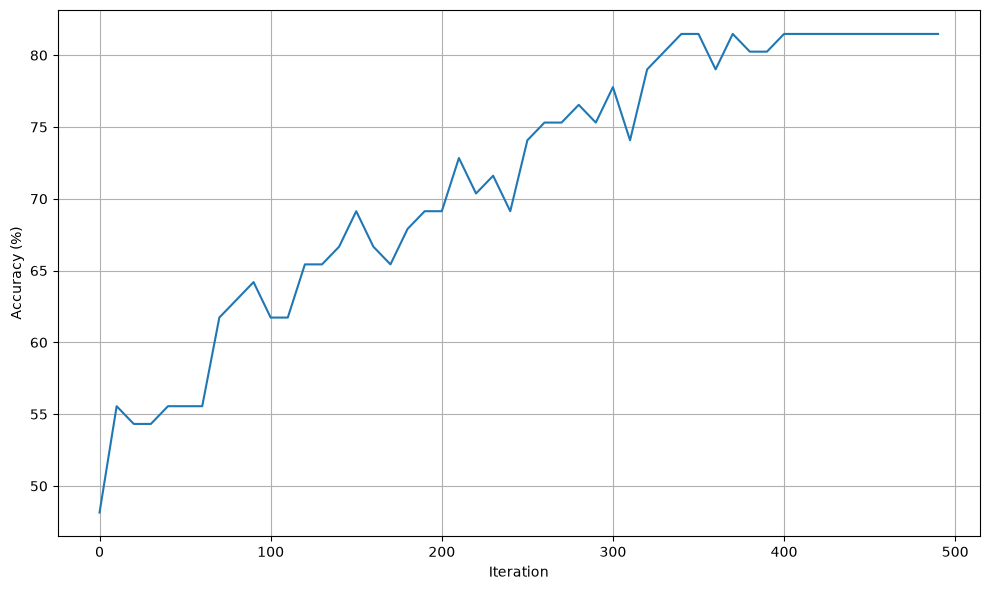

In [5]:
pbar = tqdm(range(max_iters))

for i in pbar:

    # =========================
    # 1. 학습용 문제 가져오기
    # =========================
    prompts, gts = next(data_iter)


    # =========================
    # 2. 현재 model을 old_model에 복사
    # =========================
    old_model.load_state_dict(
        model.state_dict()
    )

    old_model.eval()


    # =========================
    # 3. 각 문제마다 group_size개의 답변 생성
    # =========================
    all_prompts, all_responses, all_advantages = generate_group(
        old_model,
        tokenizer,
        prompts,
        gts,
        group_size
    )


    # =========================
    # 4. 문자열 → token
    # =========================
    ids, mask = dataset.get_batch(
        all_prompts,
        all_responses,
        device
    )

    all_advantages = all_advantages.to(device)


    # =========================
    # 5. GRPO 업데이트
    # =========================
    model.train()

    for _ in range(n_update_per_generation):

        optimizer.zero_grad()

        loss = grpo_loss(
            model,
            old_model,
            ids,
            mask,
            all_advantages,
            epsilon
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()


    # =========================
    # 6. 일정 주기마다 전체 문제 평가
    # =========================
    if i % eval_interval == 0:

        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for prompt, gt in dataset.data:

                full_text = generate(
                    model,
                    tokenizer,
                    prompt,
                    temperature=0
                )

                # prompt 제거
                response = full_text[len(prompt):]

                reward = calculate_reward(
                    gt,
                    response
                )

                if reward > 0:
                    correct += 1

                total += 1


        current_accuracy = (
            correct / total * 100
            if total > 0
            else 0.0
        )

        accuracies.append(
            current_accuracy
        )

        pbar.set_postfix({
            "loss": f"{loss.item():.4f}",
            "acc": f"{current_accuracy:.2f}%"
        })

        model.train()


# =========================
# 7. GRPO 모델 저장
# =========================
model.save(
    grpo_model_save_path
)


# =========================
# 8. Accuracy 그래프
# =========================
plt.figure(figsize=(10, 6))

steps = list(
    range(
        0,
        len(accuracies) * eval_interval,
        eval_interval
    )
)

plt.plot(
    steps,
    accuracies
)

plt.xlabel("Iteration")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.show()